# COSC 520 Assignment 2

B-tree, B+ tree and skip list: insertion, search and deletion. Setup and methodology are in [README](../README.md).

## 1. Setup

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import json
import math
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "cosc520_assignment2").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "cosc520_assignment2").exists(), "Run from the project root or its notebooks directory."
sys.path.insert(0, str(ROOT / "src"))

from IPython.display import display, Markdown
%matplotlib inline
from matplotlib import pyplot as plt
from cosc520_assignment2.benchmark import StructureConfig
from cosc520_assignment2.experiments import run_experiments
from cosc520_assignment2.plotting import (
    LABELS, OPERATIONS, load_results, summarize_timings, plot_runtimes, plot_peak_memory,
)
plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "font.family": "DejaVu Sans"})

def show_and_save(figure, name):
    for extension in ("png", "pdf"):
        figure.savefig(FIGURE_DIR / f"{name}.{extension}", dpi=180, bbox_inches="tight")
    display(figure)
    plt.close(figure)

print("Python:", sys.version.split()[0])

Matplotlib is building the font cache; this may take a moment.


Python: 3.12.12


## 2. Configuration

Keep `RUN_NEW_EXPERIMENTS = False` to plot saved results. Set it to `True` to generate inputs and measure again. Parameters below apply to new runs.

In [2]:
RUN_NEW_EXPERIMENTS = False
SIZES = (1_000, 10_000, 100_000, 1_000_000, 3_000_000, 10_000_000)
QUERIES = 100_000
REPEATS = 3
SEED = 42
ORDERS = ("random",)
SELECTED_ORDER = "random"
DATA_DIR = ROOT / "data" / f"generated-seed-{SEED}-queries-{QUERIES}"
LATEST_RUN = ROOT / "results" / "latest-notebook-run.txt"
EXISTING_RUN = ROOT / "results" / LATEST_RUN.read_text().strip() if LATEST_RUN.exists() else None
CONFIG = StructureConfig(max_keys=63, probability=0.5, max_level=32, validate_structure=False)
CONFIG.validate()

## 3. Run or load

Saved measurements predate the B-tree search refactor; a new run measures the current source.

In [3]:
if RUN_NEW_EXPERIMENTS:
    OUTPUT_DIR = ROOT / "results" / datetime.now(timezone.utc).strftime("notebook-%Y%m%dT%H%M%S%fZ")
    progress = display("Preparing workloads...", display_id=True)
    records = run_experiments(
        sizes=SIZES, queries=QUERIES, repeats=REPEATS, seed=SEED, orders=ORDERS,
        data_dir=DATA_DIR, output_dir=OUTPUT_DIR, config=CONFIG,
        progress=lambda message: progress.update(message),
    )
    progress.update("Measurements finished; checking completeness below.")
else:
    assert EXISTING_RUN is not None, "No saved run: set RUN_NEW_EXPERIMENTS = True."
    OUTPUT_DIR = EXISTING_RUN
    records = load_results(OUTPUT_DIR / "raw.csv")

metadata = json.loads((OUTPUT_DIR / "environment.json").read_text())
actual = json.loads((OUTPUT_DIR / "experiment.json").read_text())
assert metadata["status"] == "complete", "Run incomplete; inspect raw.csv and jobs/*.log."
assert all(r["status"] == "ok" for r in records), "Failed runs cannot support timing claims."
expected = {(name, size, repeat, order, operation)
            for name in LABELS for size in actual["sizes"]
            for repeat in range(actual["repeats"]) for order in actual["orders"] for operation in OPERATIONS}
observed = {(r["structure"], r["n"], r["repeat"], r["order"], r["operation"]) for r in records}
assert observed == expected and len(records) == len(expected), "Missing or duplicate measurements."
for r in records:
    expected_count = r["queries"] if r["operation"].startswith("search") else r["n"]
    assert r["operations"] == expected_count
    assert math.isclose(r["elapsed_ns"] / r["operations"], r["ns_per_op"], rel_tol=1e-12)
assert metadata["completed_jobs"] == len(expected) // 4
if RUN_NEW_EXPERIMENTS:
    LATEST_RUN.write_text(OUTPUT_DIR.name + "\n")
FIGURE_DIR = OUTPUT_DIR / "figures-notebook"
FIGURE_DIR.mkdir(exist_ok=True)
print("Results:", OUTPUT_DIR.relative_to(ROOT))
print("Sizes:", ", ".join(f"{n:,}" for n in actual["sizes"]))
print(f"{actual['repeats']} repetitions | {actual['queries']:,} queries/category | {len(records)} valid measurements")

Results: results/notebook-20261023T183203045636Z
Sizes: 1,000, 10,000, 100,000, 1,000,000, 3,000,000, 10,000,000
3 repetitions | 100,000 queries/category | 216 valid measurements


## 4. Operation latency

Median microseconds per operation; shaded bands show IQR, not confidence intervals.

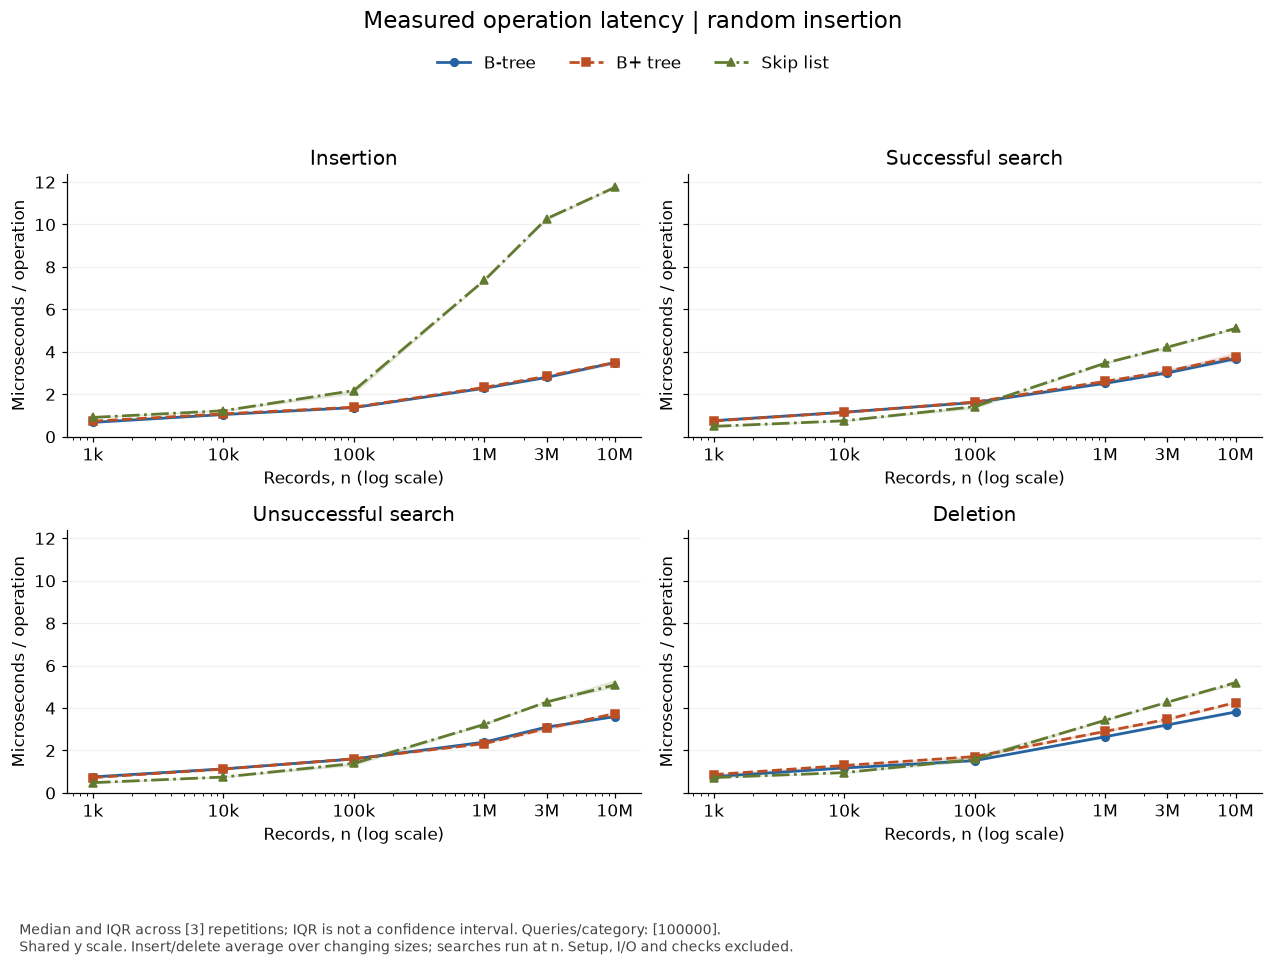

In [4]:
show_and_save(plot_runtimes(records, order=SELECTED_ORDER), "operation-latency")

### Largest measured size

In [5]:
summaries = summarize_timings(records, order=SELECTED_ORDER)
LARGEST_N = max(s["n"] for s in summaries)
lookup = {(s["structure"], s["operation"]): s for s in summaries if s["n"] == LARGEST_N}
lines = [f"**n = {LARGEST_N:,}; {SELECTED_ORDER} insertion**", "",
         "| Structure | Insert (µs/op) | Search hit (µs/op) | Search miss (µs/op) | Delete (µs/op) |",
         "|---|---:|---:|---:|---:|"]
for name, label in LABELS.items():
    values = [f"{lookup[name, operation]['median']:.3f}" for operation in OPERATIONS]
    lines.append("| " + " | ".join([label, *values]) + " |")
display(Markdown("\n".join(lines)))

**n = 10,000,000; random insertion**

| Structure | Insert (µs/op) | Search hit (µs/op) | Search miss (µs/op) | Delete (µs/op) |
|---|---:|---:|---:|---:|
| B-tree | 3.493 | 3.679 | 3.596 | 3.816 |
| B+ tree | 3.494 | 3.775 | 3.737 | 4.260 |
| Skip list | 11.749 | 5.103 | 5.090 | 5.200 |

## 5. Peak process memory

Whole-worker peak RSS includes Python, inputs and buffers.

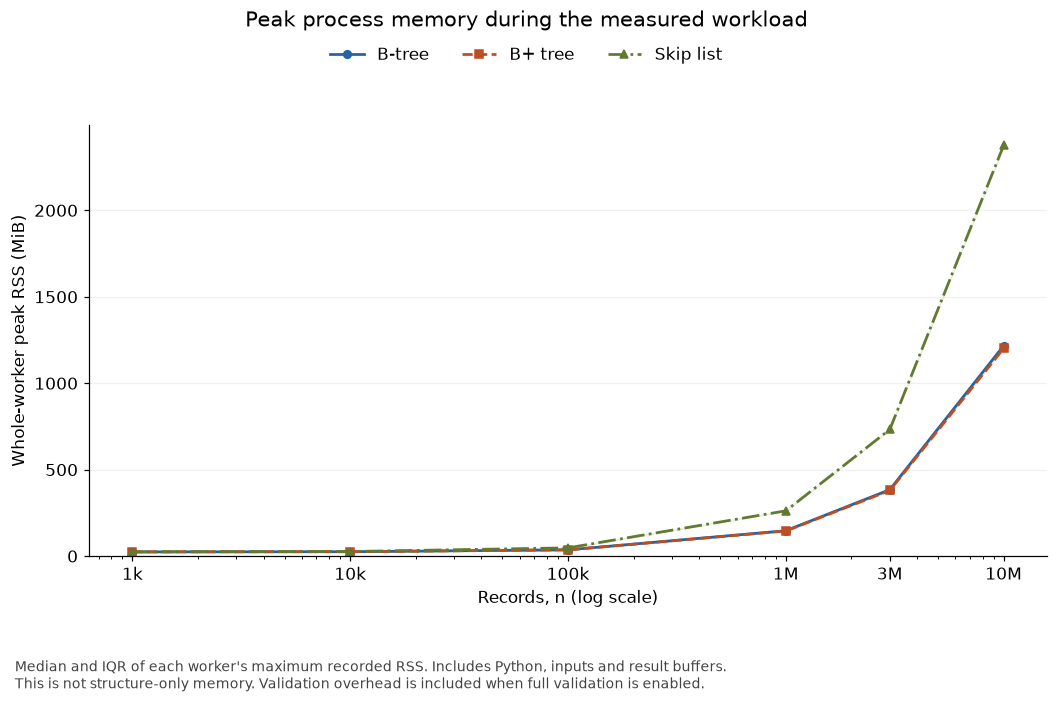

In [6]:
show_and_save(plot_peak_memory(records, order=SELECTED_ORDER), "peak-process-memory")